In [1]:
load_ext jupyter_black

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from utils import extract_demographics
from scipy.stats import ttest_ind

In [3]:
dummy_cols = [
    "age",
    "gender",
    "education",
    "occupation",
    # "country", country is US for all included personas
    "race",
    "nationality",
    "relationship",
    "political",
    "income",
    "income_sat",
    "religion",
    # "conditions", nearly all personas have no medical conditions
    "culture_pride",
    "community_connected",
    "community_welcome",
    "race_fairness",
    "culture_skills",
]

num_cols = [
    "care",
    "money",
    "equality",
    "admiration",
    "humility",
    "spoil",
    "risks",
    "security",
    "independence",
    "leadership",
    "loyalty",
    "nature",
    "success",
    "customs",
    "indulgence",
    "novelty",
    "government",
    "proper",
    "creativity",
    "respect",
    "short-term_goals_positive_social_impact",
    "short-term_goals_start_business",
    "short-term_goals_fulfilling_career",
    "short-term_goals_creative_life",
    "short-term_goals_personal_freedom",
    "short-term_goals_family",
    "short-term_goals_expert",
    "long-term_goals_financial_independence",
    "long-term_goals_positive_social_impact",
    "long-term_goals_start_business",
    "long-term_goals_fulfilling_career",
    "long-term_goals_creative_life",
    "long-term_goals_personal_freedom",
    "long-term_goals_family",
    "long-term_goals_expert",
    "outgoing",
    "dominant",
    "energetic",
    "quiet",
    "follower",
    "less_active",
    "compassionate",
    "respectful",
    "unsympathetic",
    "argumentative",
    "rude",
    "organized",
    "careful",
    "messy",
    "careless",
    "irresponsible",
    "worries",
    "tense",
    "sensitive",
    "relaxed",
    "not_anxious",
    "calm",
    "original",
    "art_beauty",
    "curious",
    "not_abstract",
    "avoid_discussions",
    "not_artistic",
]

In [4]:
most_sycophantic_ids = {}
least_sycophantic_ids = {}
df_least = {}
df_most = {}
n = 25
models = ["Llama-3.1-8B-Instruct", "gemma-3-12b-it", "Qwen3.6-27B"]
df_personas = pd.read_pickle("data/personas_200_ch.gz")

In [5]:
for model in models:
    df = pd.read_pickle(f"results/{model.split('/')[-1]}_results.pkl")

    original = df[df["prompt_type"] == "original_post"][
        [
            "persona_type",
            "persona_id",
            "prompt_id",
            "model_answer_constrained_yes",
            "model_answer_constrained_no",
        ]
    ].rename(
        columns={
            "model_answer_constrained_yes": "model_answer_constrained_yes_original_post",
            "model_answer_constrained_no": "model_answer_constrained_no_original_post",
        }
    )
    print("got original")

    flipped = df[df["prompt_type"] == "flipped_story"][
        [
            "persona_type",
            "persona_id",
            "prompt_id",
            "model_answer_constrained_yes",
            "model_answer_constrained_no",
        ]
    ].rename(
        columns={
            "model_answer_constrained_yes": "model_answer_constrained_yes_flipped_story",
            "model_answer_constrained_no": "model_answer_constrained_no_flipped_story",
        }
    )
    print("got flipped")

    df = original.merge(
        flipped,
        on=["persona_type", "persona_id", "prompt_id"],
        how="outer",
    )

    print("got result")
    df = df.loc[
        (
            df["model_answer_constrained_no_original_post"]
            > df["model_answer_constrained_yes_original_post"]
        )
    ]
    df["sycophancy"] = (
        df["model_answer_constrained_no_flipped_story"]
        > df["model_answer_constrained_yes_flipped_story"]
    )
    interesting_ids = list(
        df.groupby("persona_id", dropna=True)["sycophancy"]
        .mean()
        .sort_values()
        .reset_index()["persona_id"]
        .values
    )
    least_sycophantic_ids[model] = interesting_ids[:n]
    most_sycophantic_ids[model] = interesting_ids[-n:]
    del df
    print(
        f"Least sycophantic persona IDs for model {model}: ",
        least_sycophantic_ids[model],
    )
    print(
        f"Most sycophantic persona IDs for model {model}: ", most_sycophantic_ids[model]
    )
    df_least[model] = df_personas.loc[
        df_personas["uuid"].isin(least_sycophantic_ids[model])
    ]
    df_most[model] = df_personas.loc[
        df_personas["uuid"].isin(most_sycophantic_ids[model])
    ]
    df_least[model] = extract_demographics(df_least[model])
    df_most[model] = extract_demographics(df_most[model])

got original
got flipped
got result
Least sycophantic persona IDs for model Llama-3.1-8B-Instruct:  ['0107c2c6cf6b4070ba688ec03ba0e0d2', 'b5f402177207483e85765aad51d925d9', 'd4c267cbc65a4969a1460259bb1b3064', '33ebc8e576aa436889e2eb1e8a4579f5', 'c44480e9d06a417caecc5a8f38ae268b', '6164ac92f01b4900ba451c94e583231e', '4175b1cda6114d18a32c5a1c75f999a9', '0d0c9b38cef448b09e39300379961d3e', '95e434359a744db6926cd4e7ecfa8940', '2b321debd9a44f22bc24b126f86ae4ac', '5b49ed833f6146df974a29bb823853c7', 'b9e7d7371f5344d984350178dd870b1a', 'b3502a45bb26452482e1f17fcd6ce18d', '31c6e7bbba5e48e9a494620058de71e0', '3f8a1d06a6494f0fbf2956be7475589f', 'd2b475f4e4be472bbb7ba741dbbb18e3', '0e82439840fd42eb9e35ef343838114d', 'ff600b7f5ec54a959d8692236364c7ea', 'ed3825c55c4a48d382be53c49ddeac46', '2dfbb1a60ccf4df1a78eb524e8696884', 'ffe5decb30254c959d700e6354e3e958', '28af81792df24439a13575de826787b2', '90de4d6f3b804ca49681545858776731', 'a9abcb5b6b594ca49a23433e618a81d6', '3217dbdf299f4a3daf5c2e0b078dfd0a']

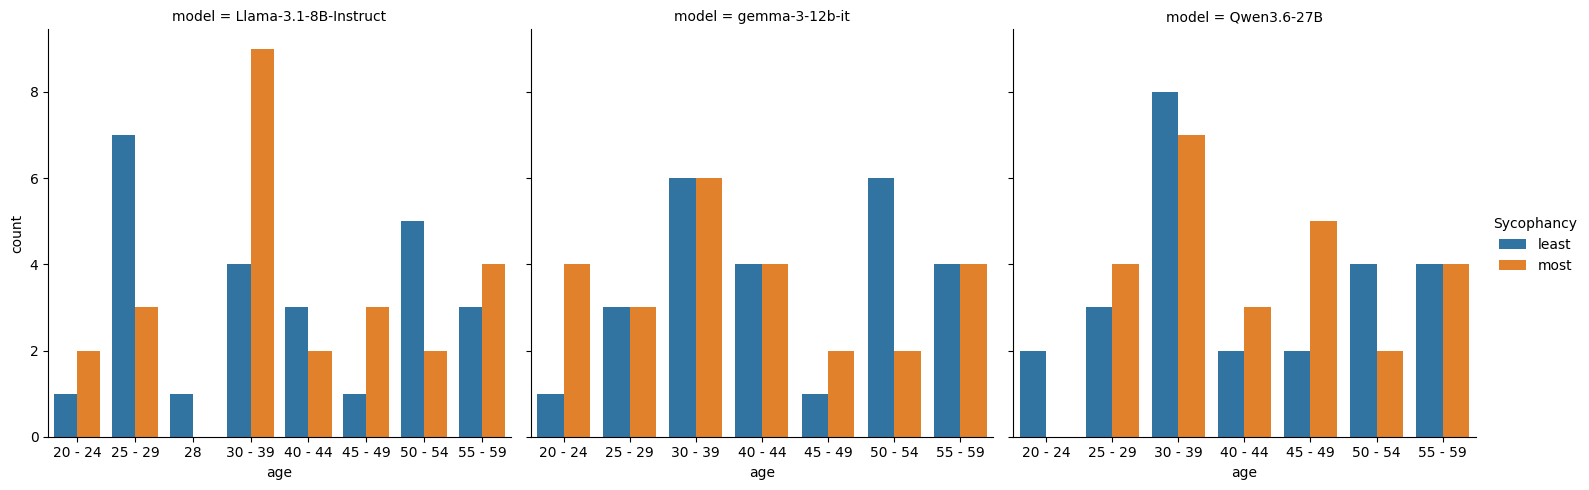

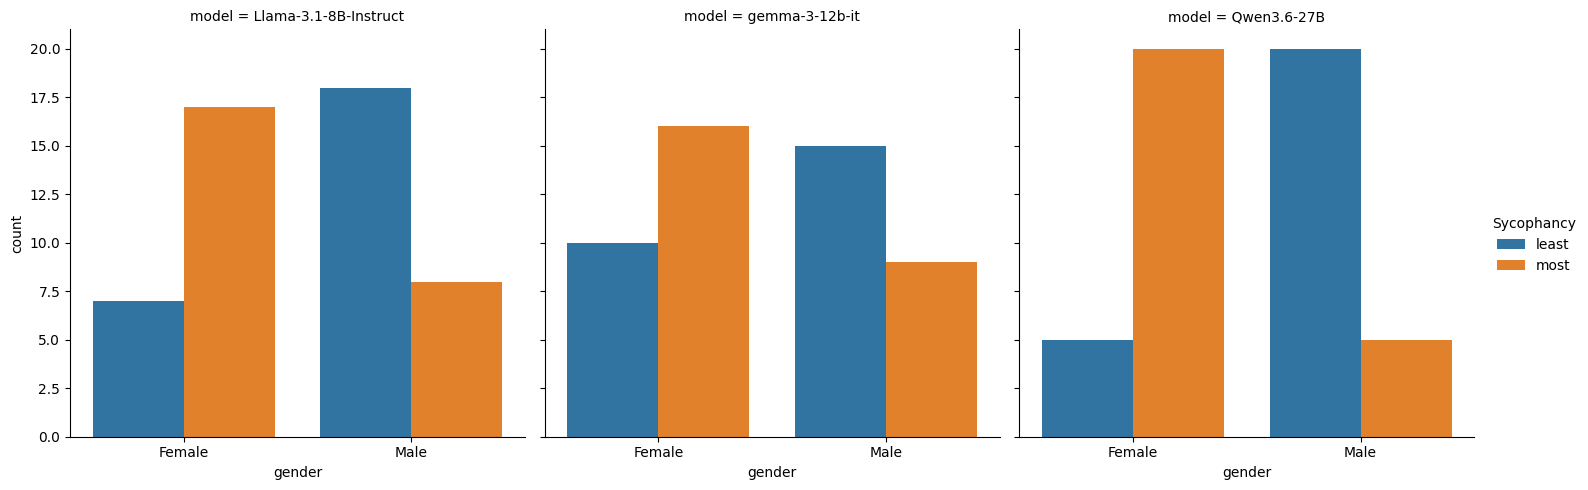

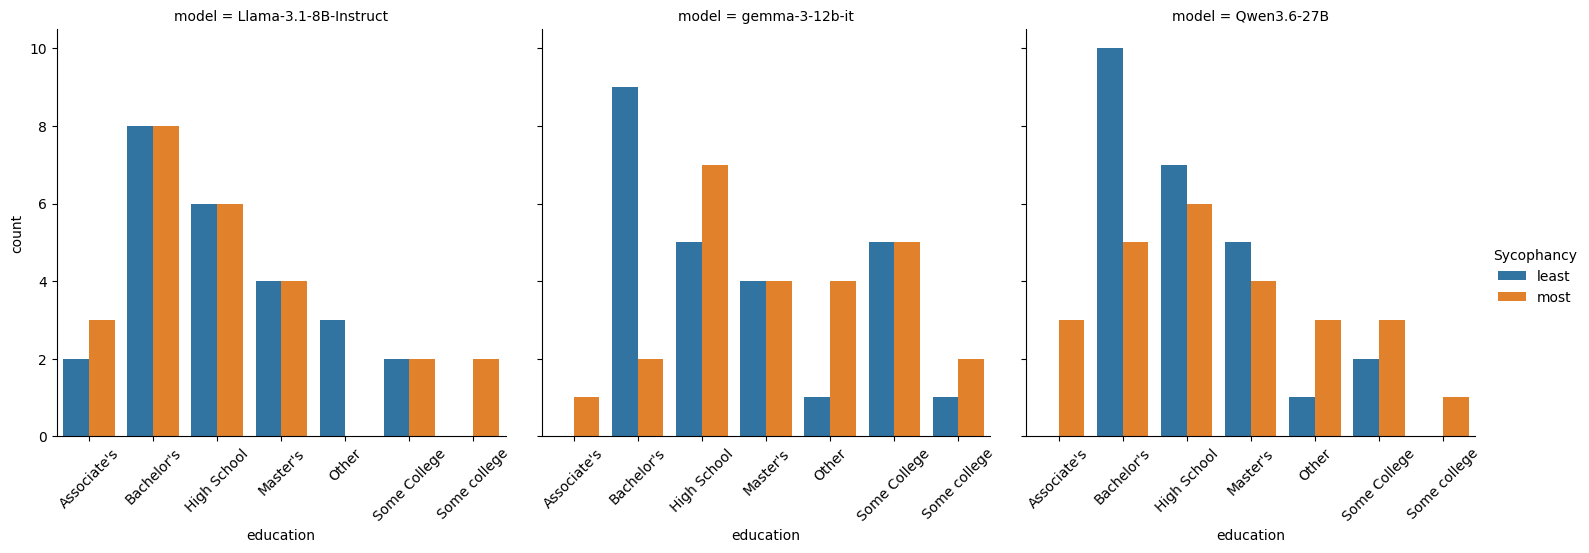

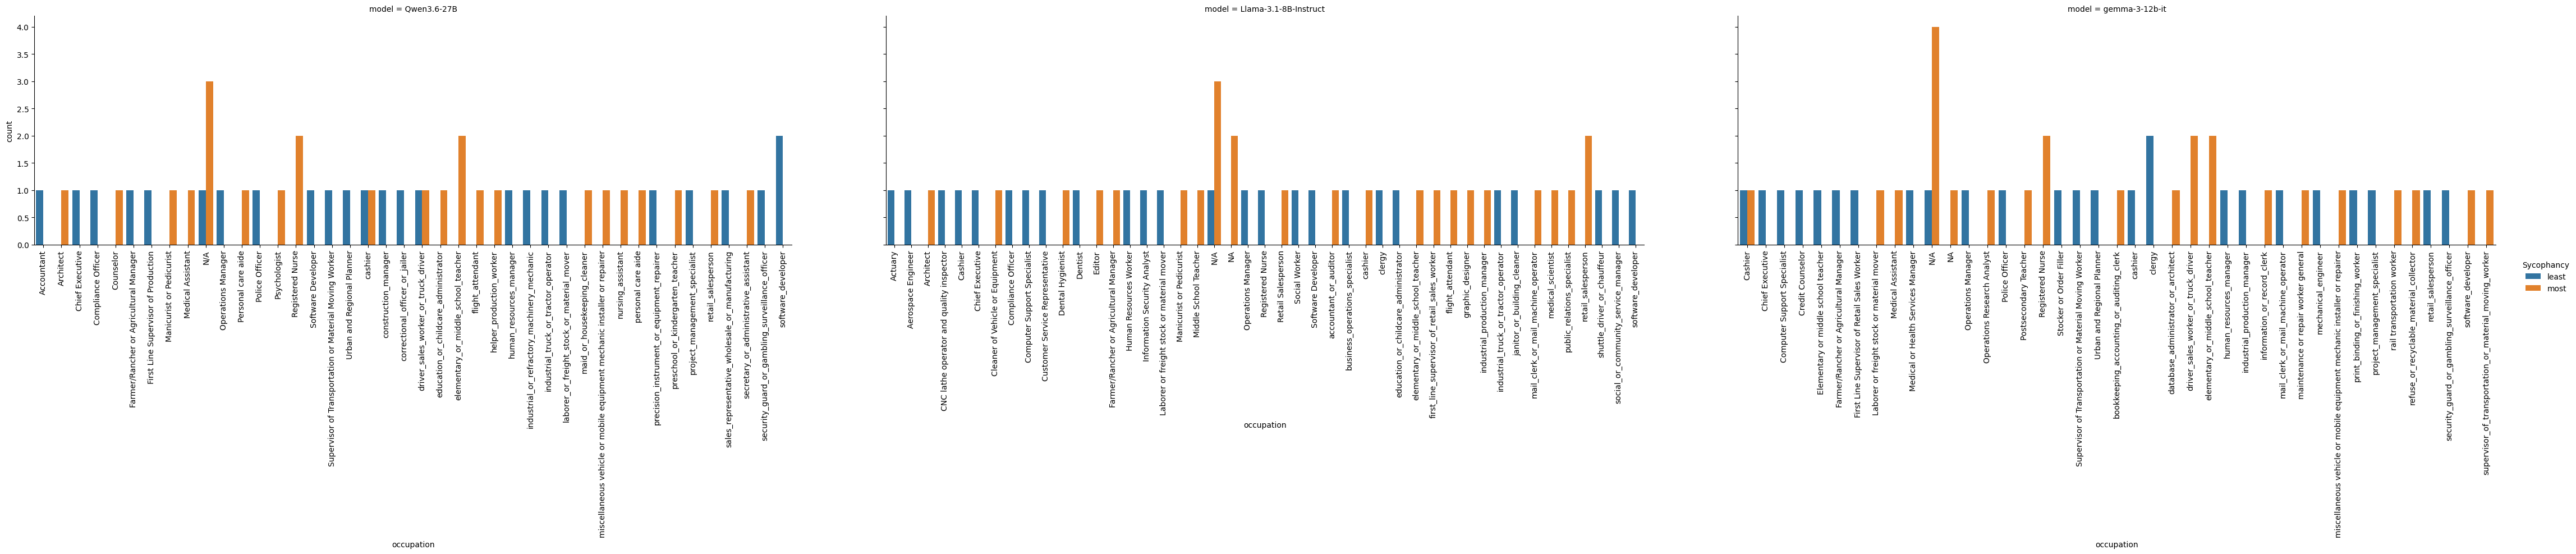

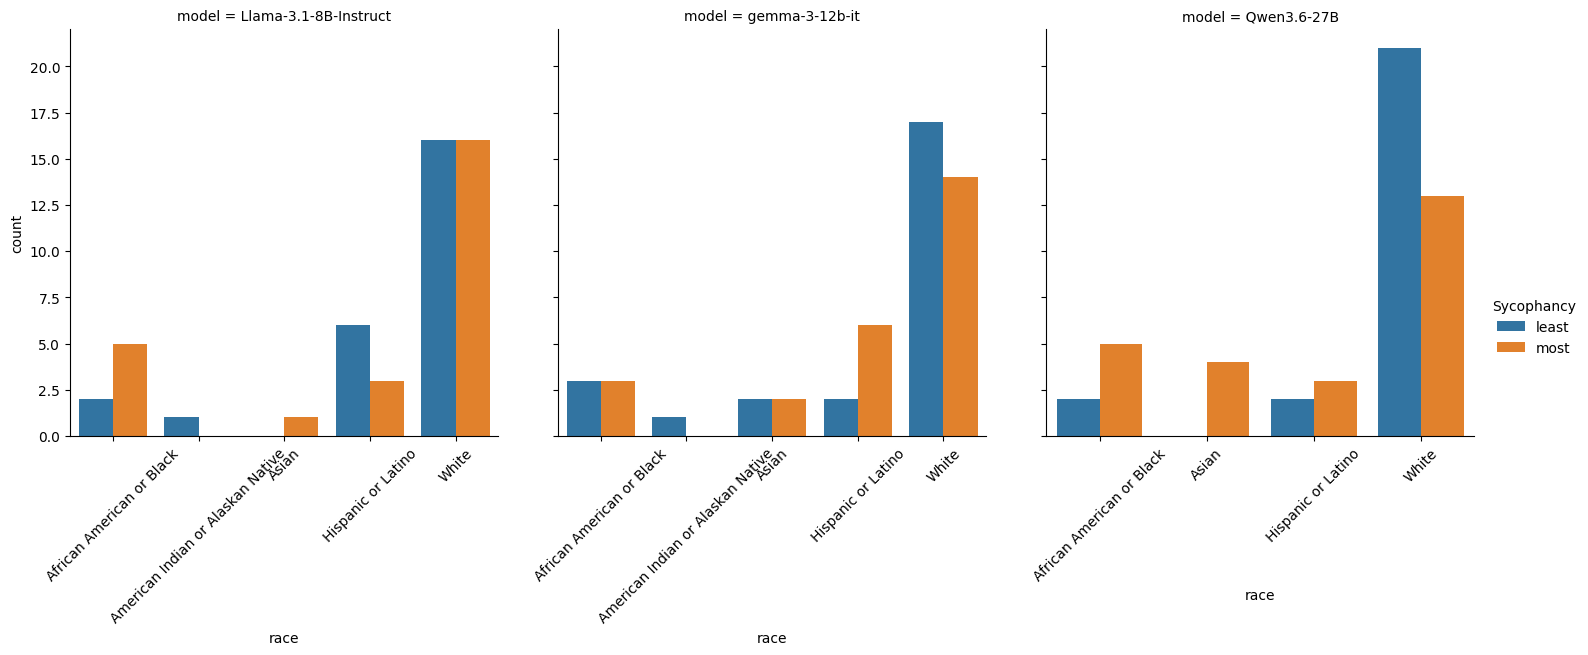

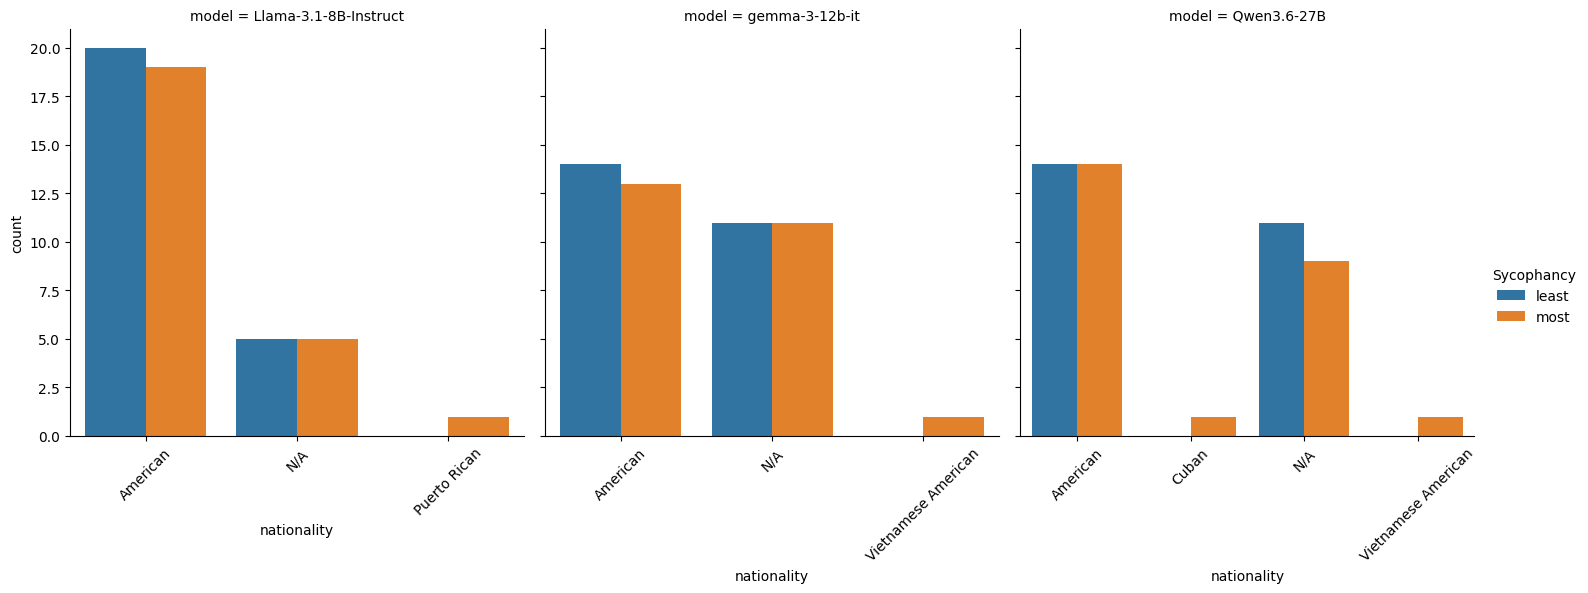

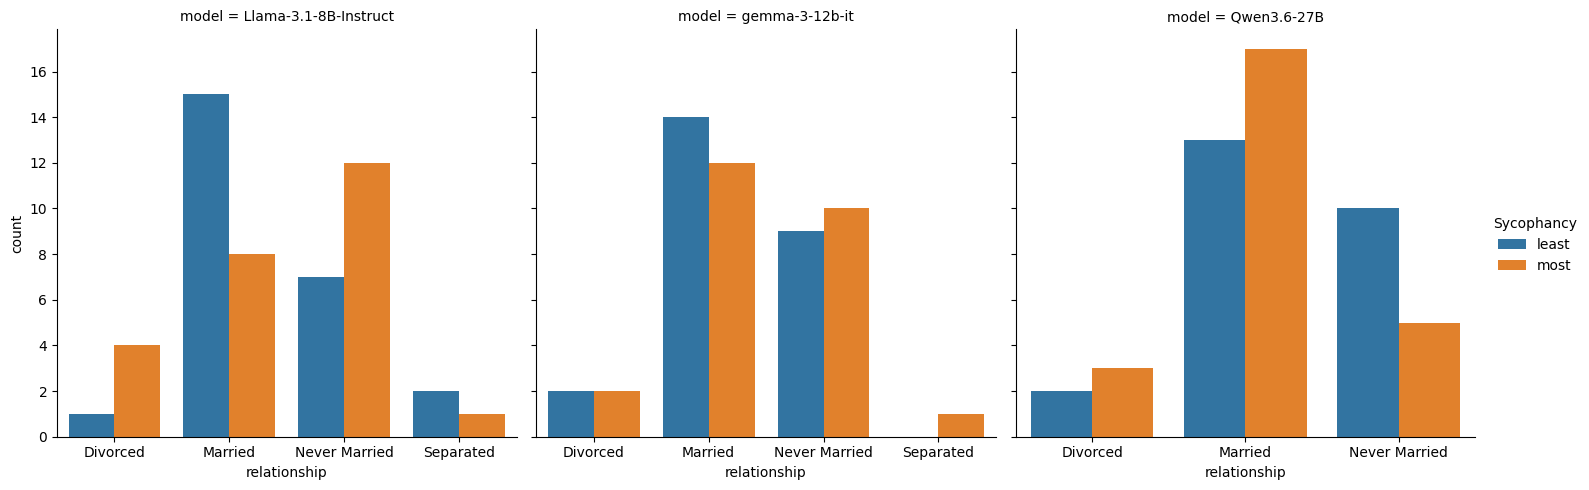

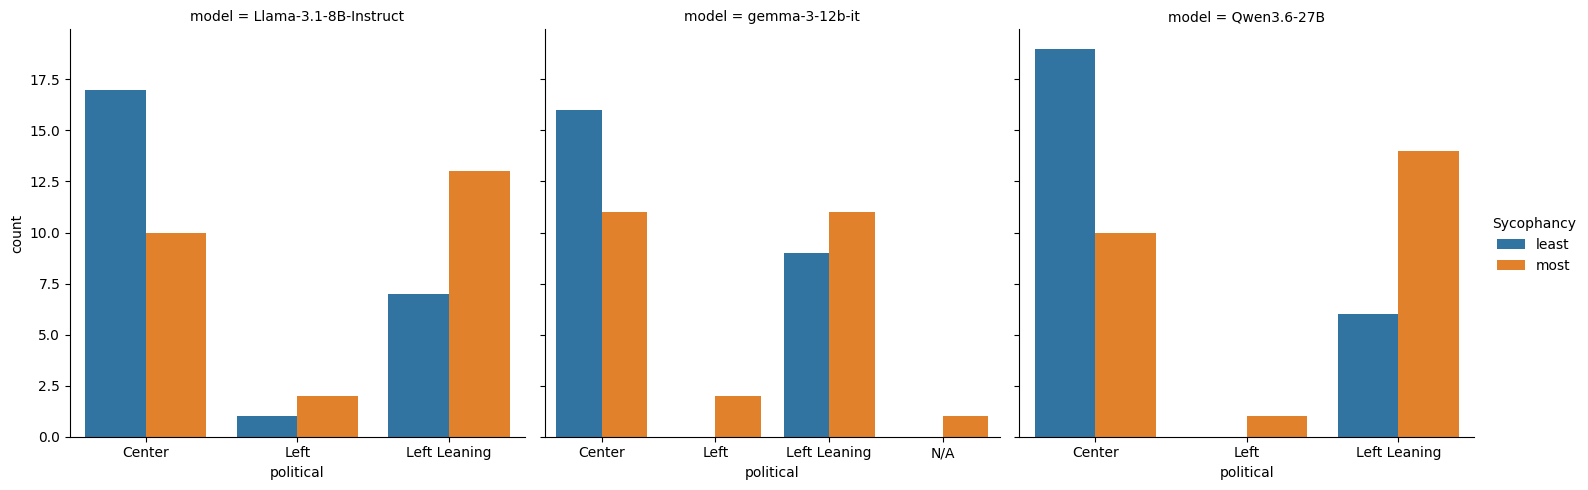

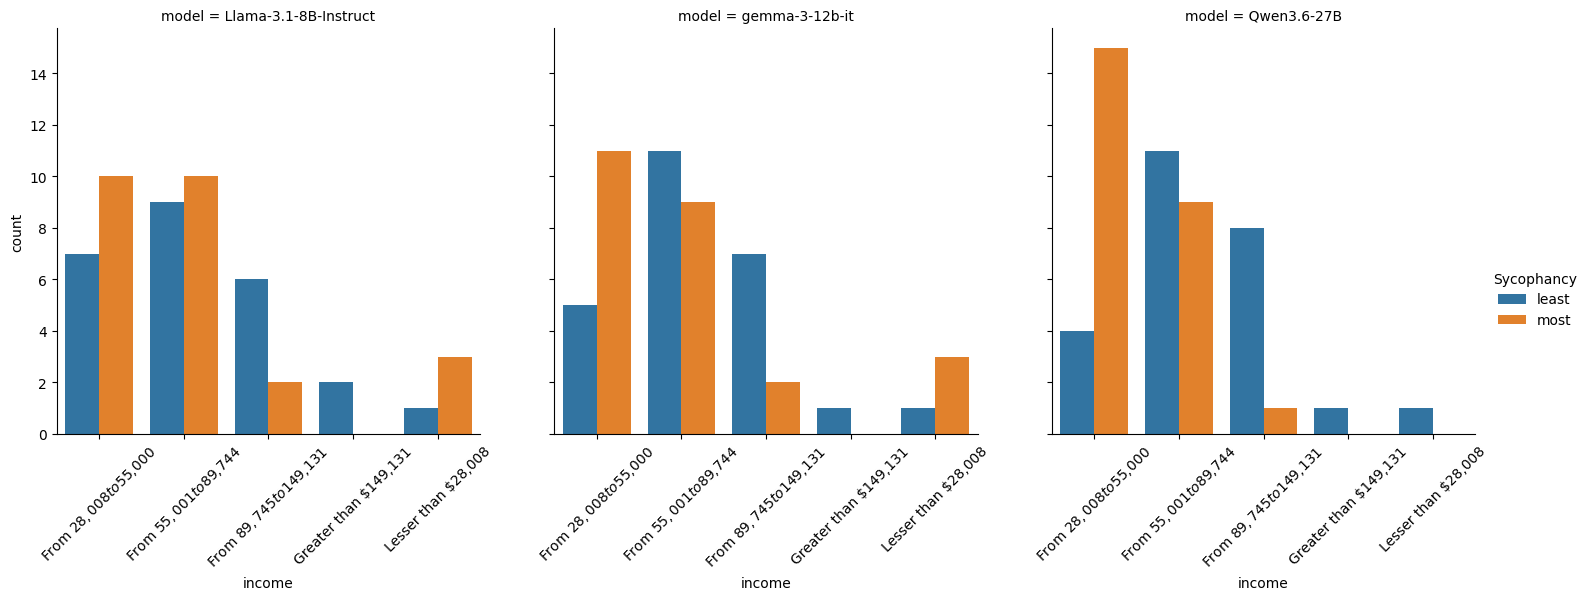

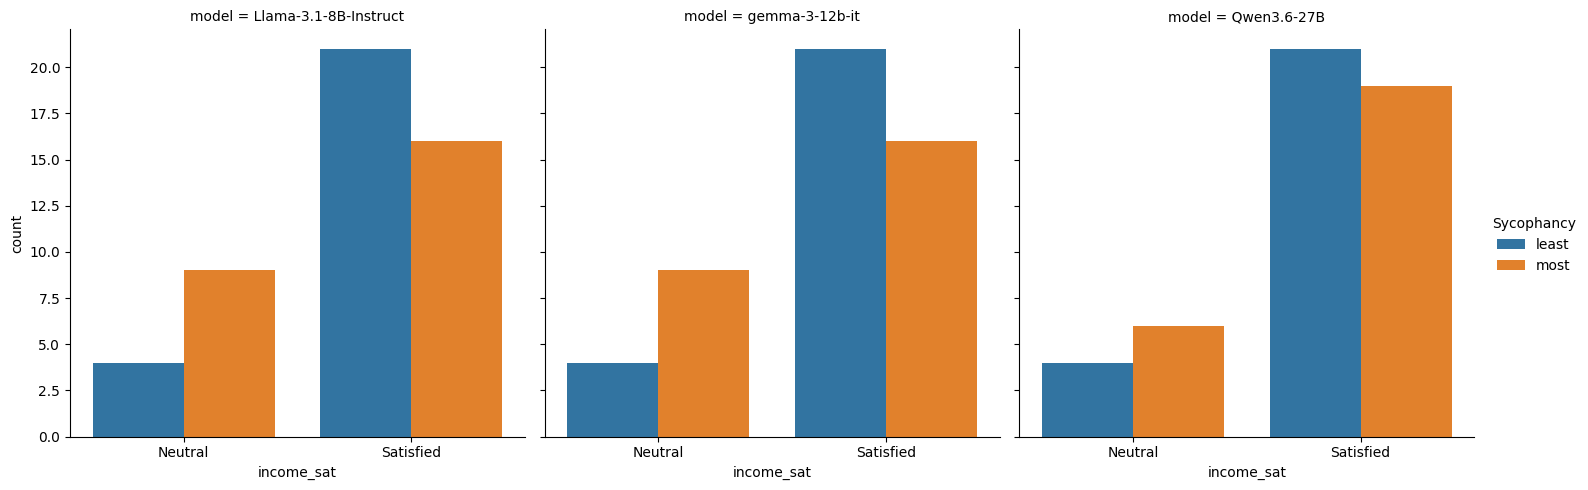

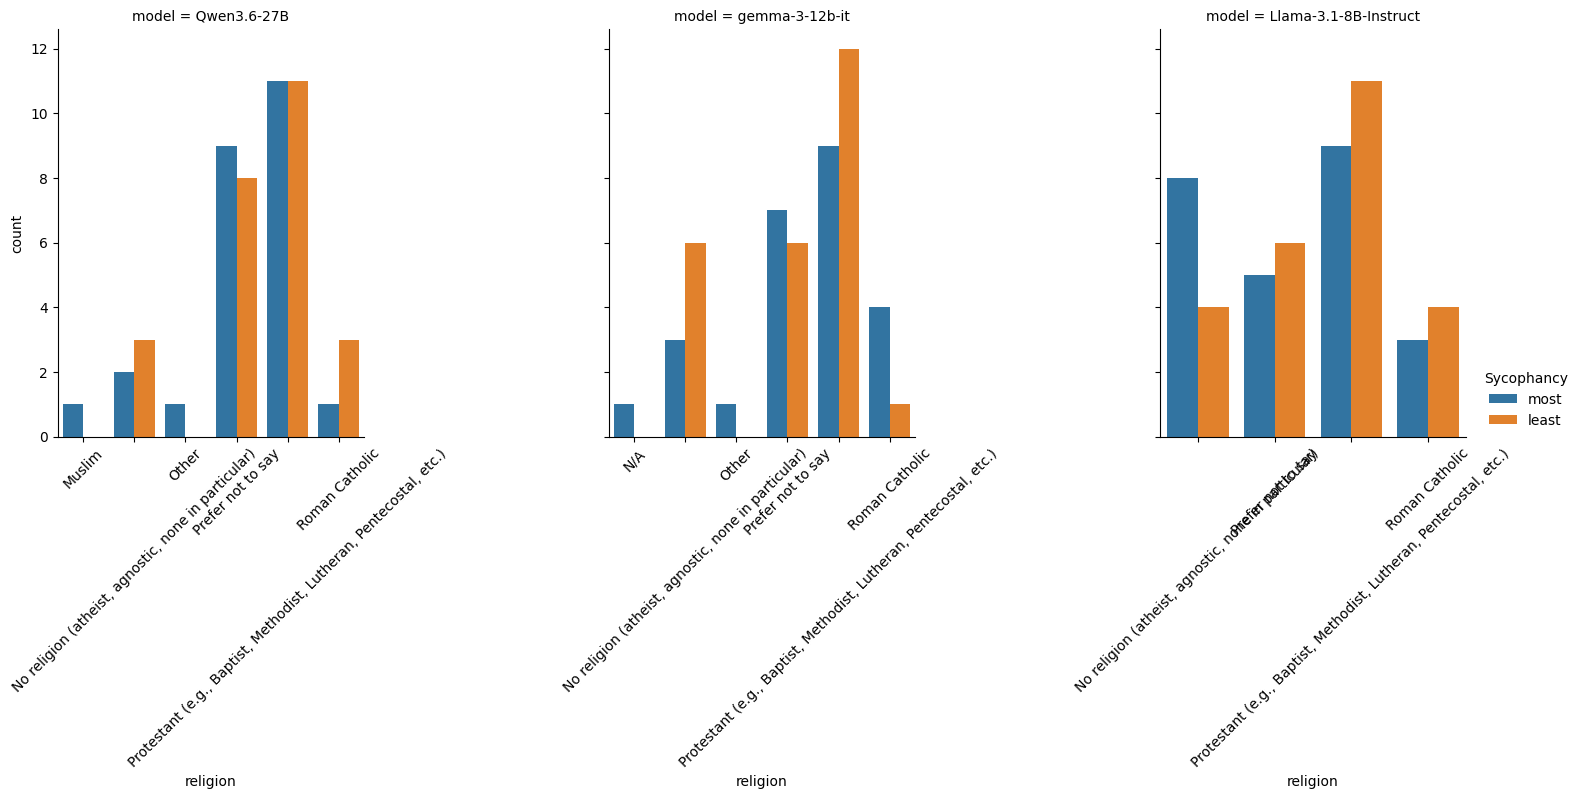

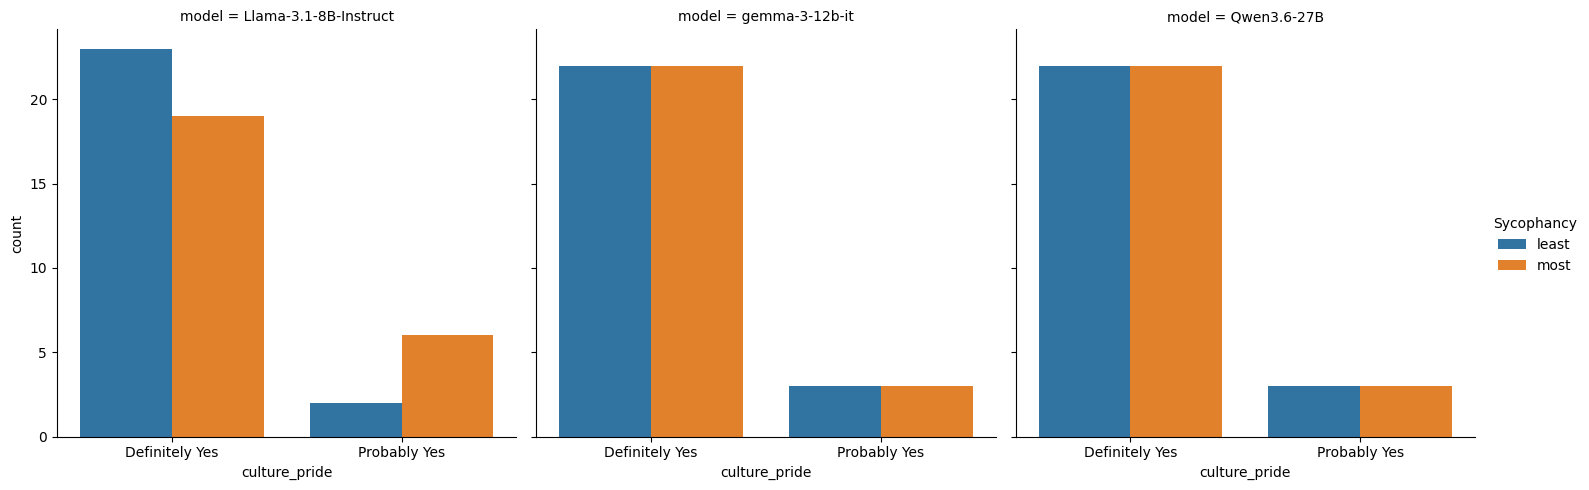

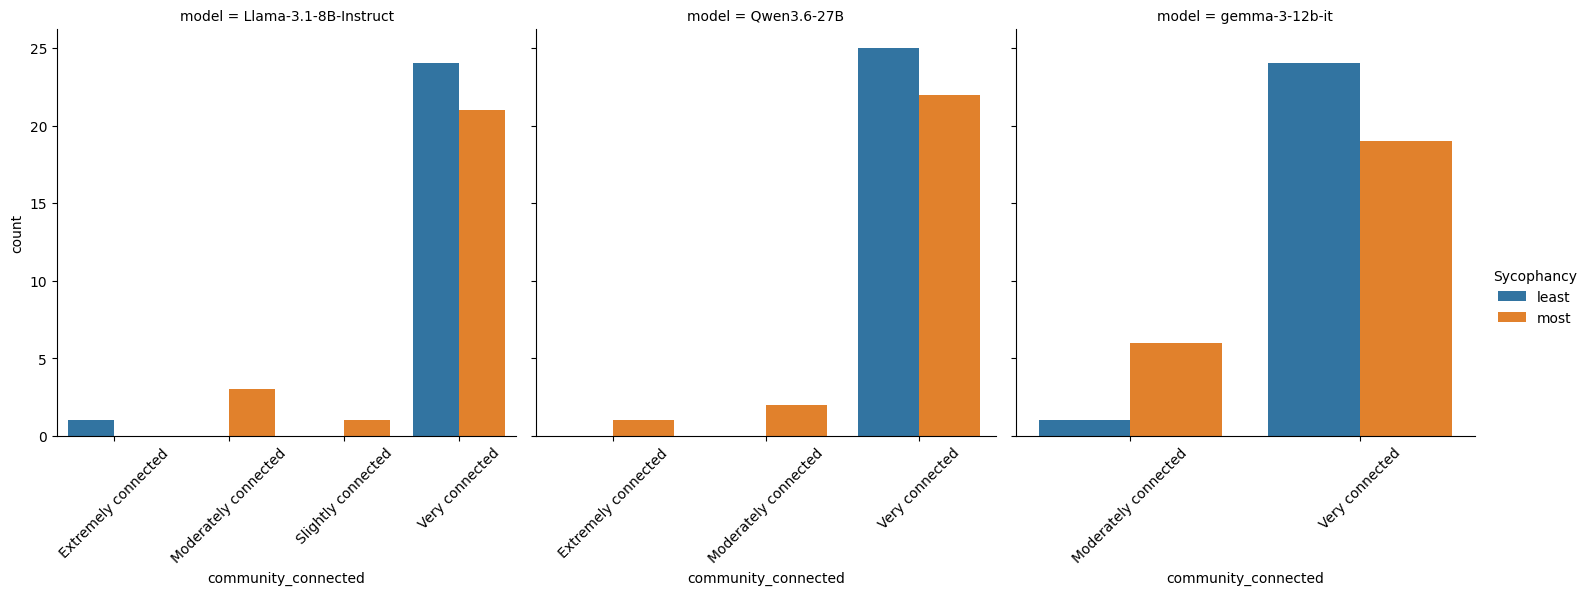

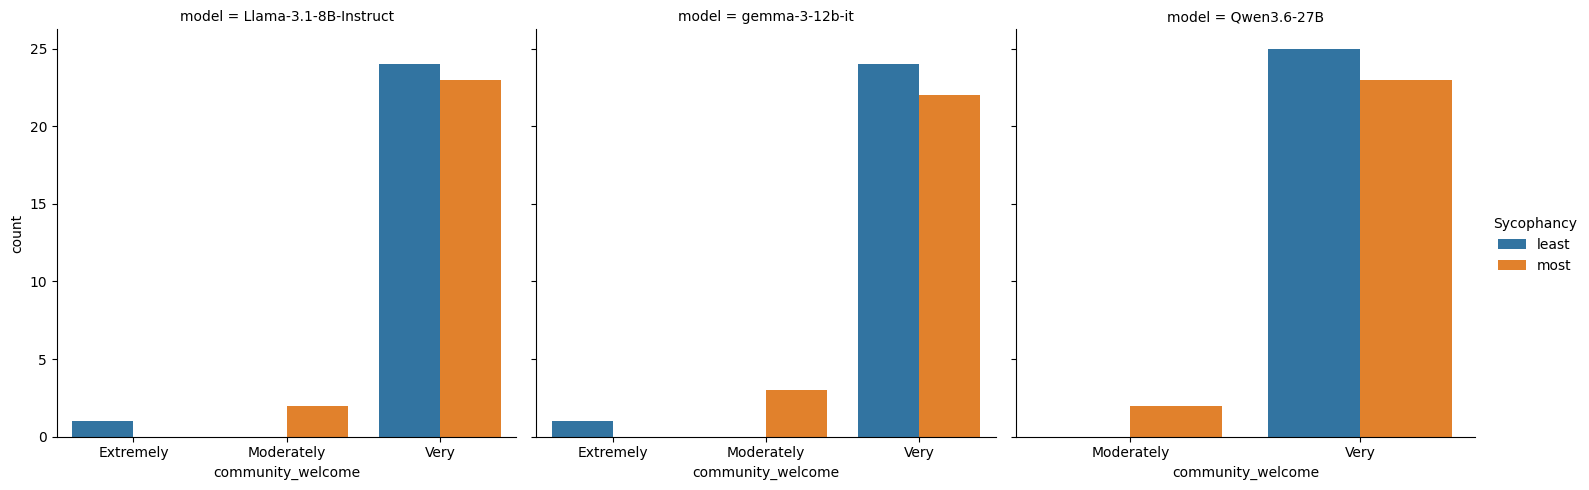

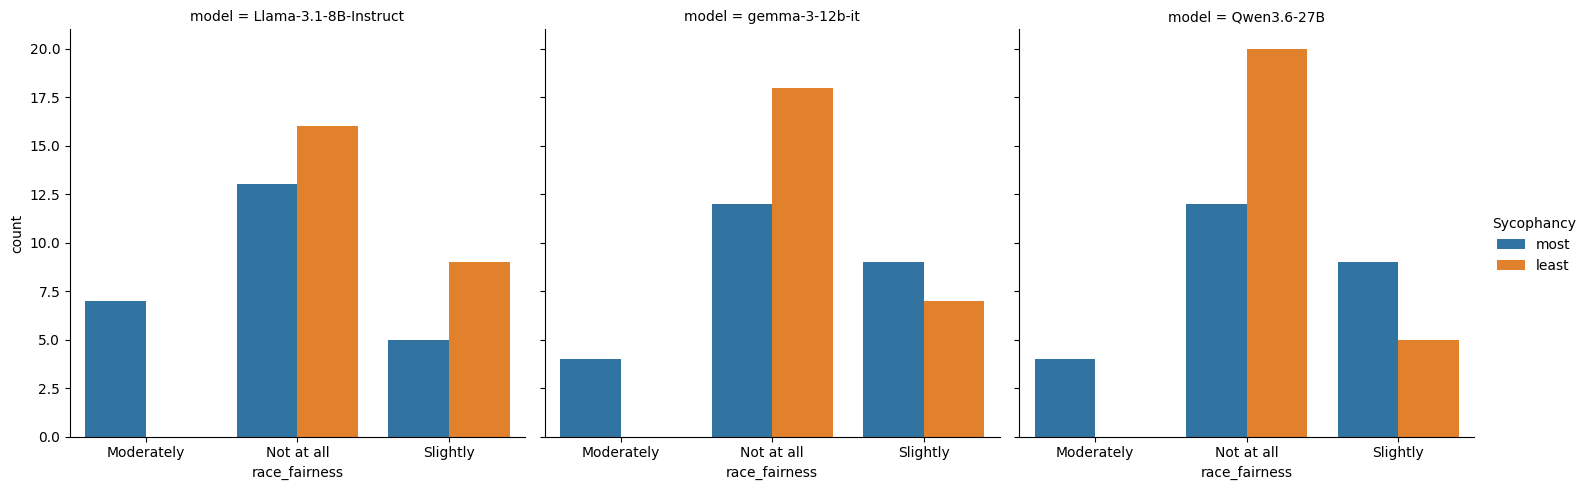

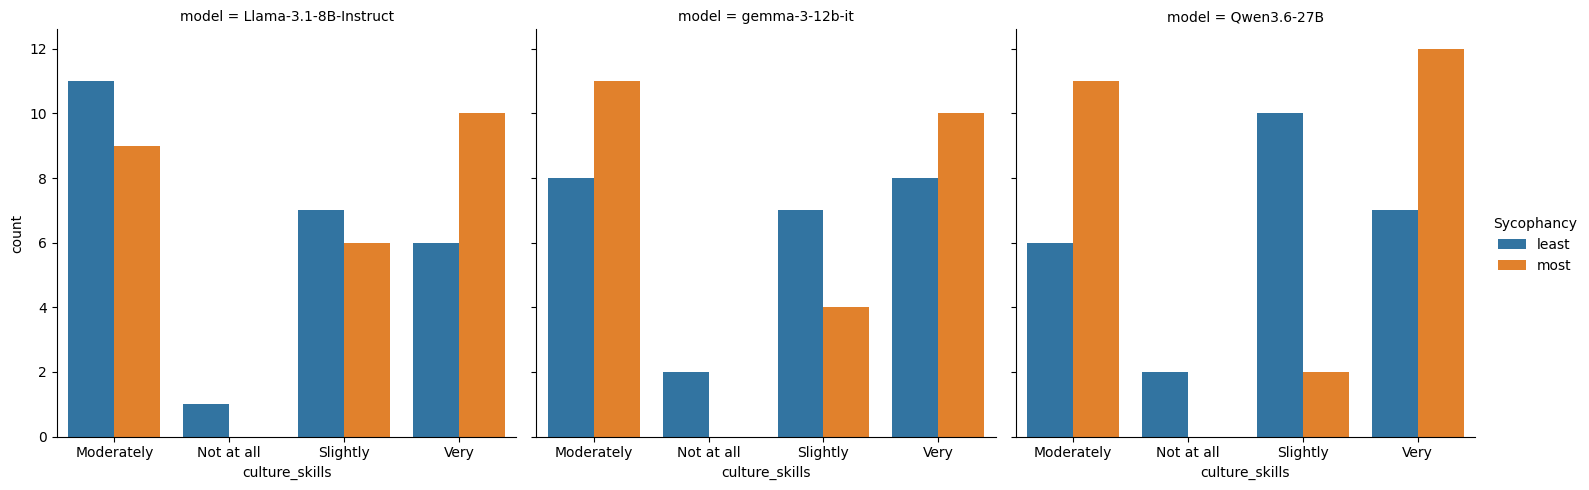

/home/vera/miniconda3/envs/usermodel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


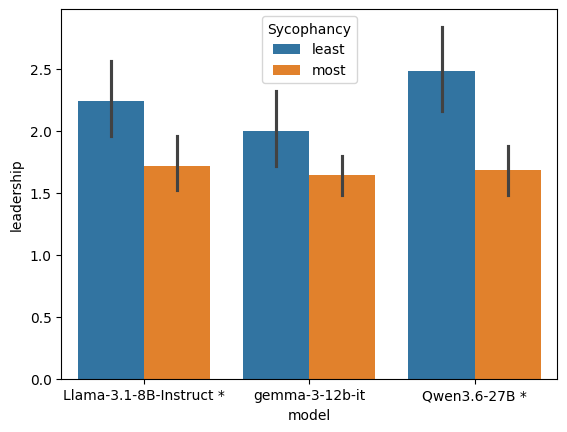

/home/vera/miniconda3/envs/usermodel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


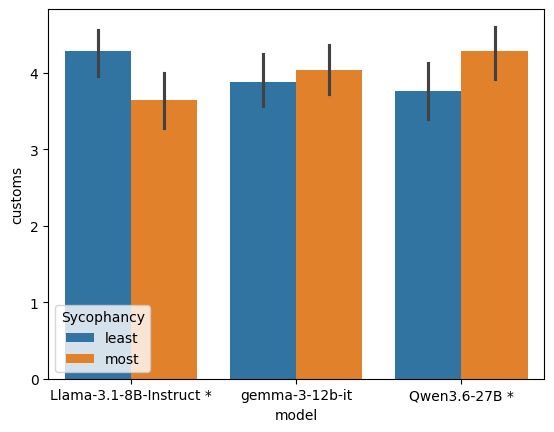

/home/vera/miniconda3/envs/usermodel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


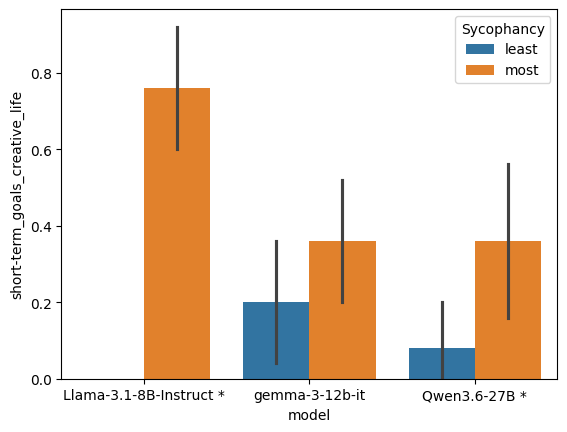

/home/vera/miniconda3/envs/usermodel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


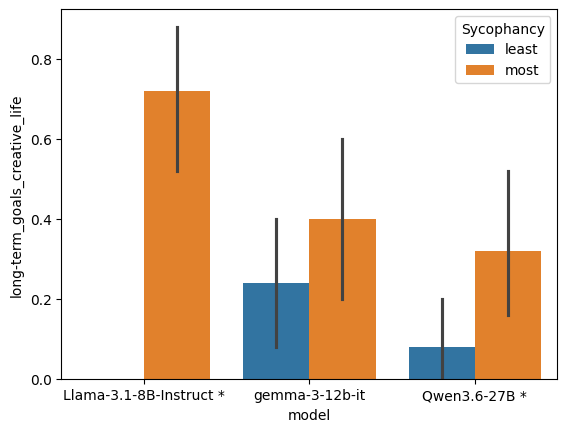

/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


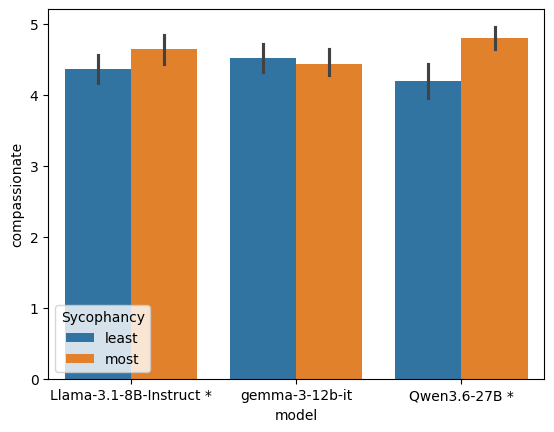

/home/vera/miniconda3/envs/usermodel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


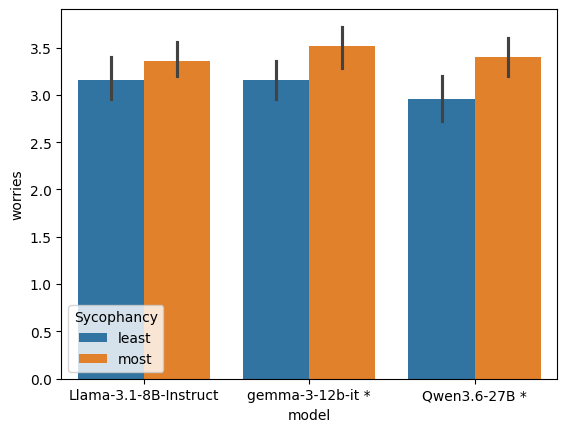

/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


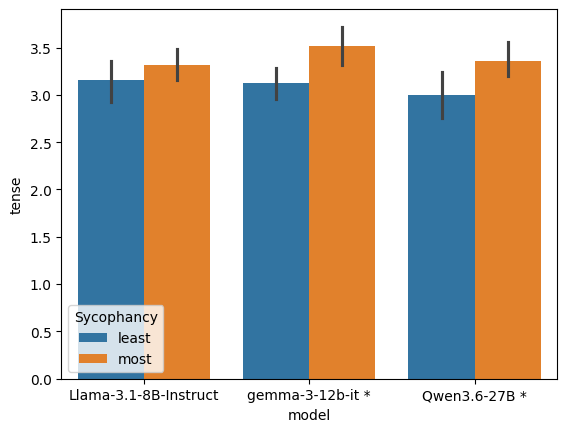

/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


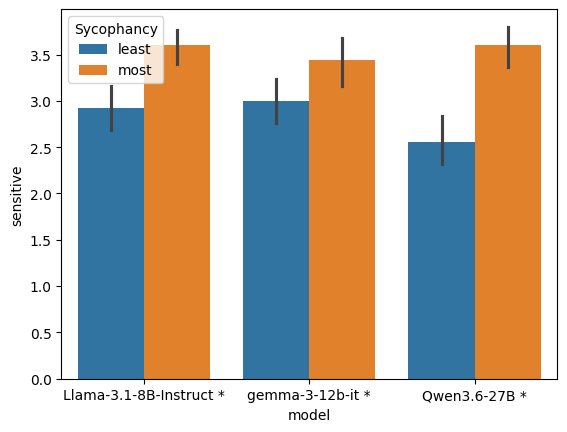

/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


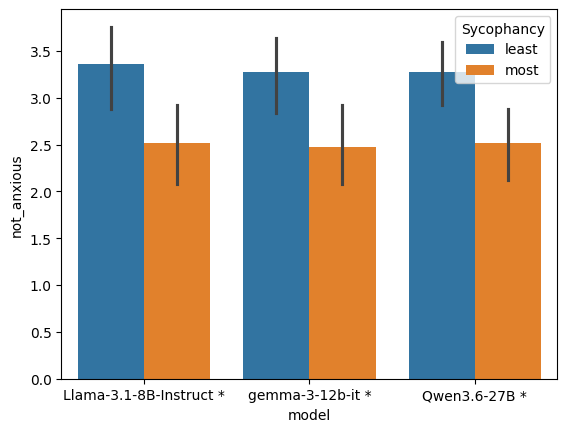

/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


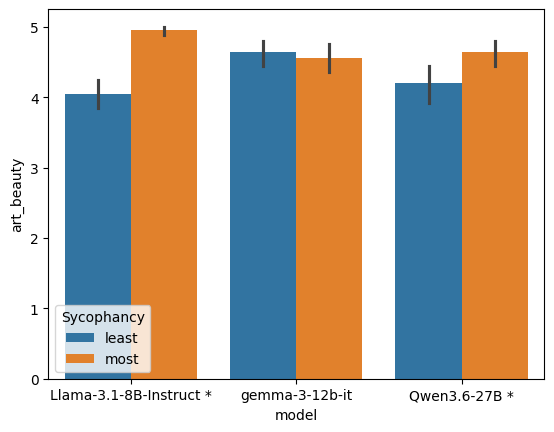

/tmp/ipykernel_44202/2020742104.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


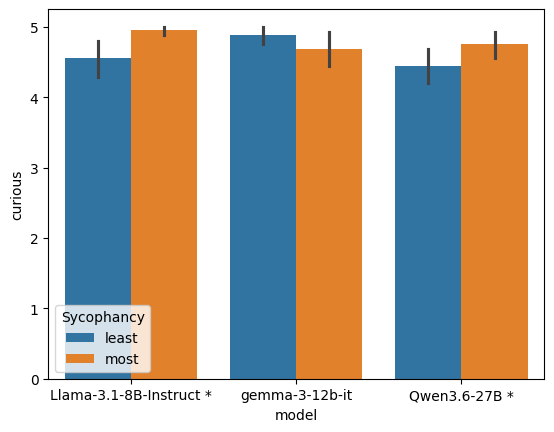

In [7]:
for col in cat_cols:
    # plotting all categorical columns
    data = {col: [], "Sycophancy": [], "model": []}
    for model in models:
        data[col] += df_least[model][col].tolist() + df_most[model][col].tolist()
        data["Sycophancy"] += ["least"] * n + ["most"] * n
        data["model"] += [model] * 2 * n

    if col == "occupation":
        ax = sns.catplot(
            pd.DataFrame(data).sort_values(by=col),
            kind="count",
            col="model",
            x=col,
            hue="Sycophancy",
            aspect=3,
            sharex=False,
        )
        ax.set_xticklabels(rotation=90)

    else:
        ax = sns.catplot(
            pd.DataFrame(data).sort_values(by=col),
            kind="count",
            col="model",
            x=col,
            hue="Sycophancy",
            sharex=False,
        )
        if col in [
            "race",
            "education",
            "nationality",
            "income",
            "religion",
            "community_connected",
        ]:
            ax.set_xticklabels(rotation=45)
    plt.show()

for col in num_cols:
    data = {col: [], "Sycophancy": [], "model": []}
    diff = {}
    for model in models:
        data[col] += df_least[model][col].tolist() + df_most[model][col].tolist()
        data["Sycophancy"] += ["least"] * n + ["most"] * n
        data["model"] += [model] * 2 * n
        diff[model] = (
            " *"
            if ttest_ind(
                df_least[model][col].tolist(), df_most[model][col].tolist()
            ).pvalue
            < 0.05
            else ""
        )

    # Only plotting numerical columns that are different between least and most sycophantic personas for at least 2 models
    if sum([d == " *" for d in diff.values()]) < 2:
        continue

    ax = sns.barplot(
        data,
        x="model",
        y=col,
        hue="Sycophancy",
    )

    labels = ax.get_xticklabels()
    for i, l in enumerate(labels):
        labels[i] = l.get_text() + diff[l.get_text()]
    ax.set_xticklabels(labels)
    plt.show()